# เทียบผลข้ามเปเปอร์ไม่ได้ — หลักฐาน

**คำถาม** เรามีตารางอุปกรณ์เพอรอฟสไกต์จากหลายสิบเปเปอร์ อยากเอามารวมกันแล้วถามว่า
*"การดัดแปลงผิว HTL แบบไหนให้ PCE สูงสุด"* หรือ *"ฝึกแบบจำลองทำนาย PCE จากสูตร + กระบวนการ"*
คำถามคือทำได้ไหม

**คำตอบสั้น ๆ** ไม่ได้ — และสมุดเล่มนี้แสดงหลักฐาน 7 ชิ้นว่าทำไม

> **อ่านก่อน** PCE (power conversion efficiency) = เปอร์เซ็นต์ของพลังงานแสงที่เซลล์เปลี่ยนเป็นไฟฟ้าได้
> ตัวเลขยิ่งสูงยิ่งดี เซลล์ที่ดีตอนนี้อยู่แถว 20–25%
> แต่ละเปเปอร์มักทำ **"เครื่องควบคุม"** (ไม่ดัดแปลงอะไร) กับ **"เครื่องที่ดัดแปลง"** เทียบกันในเปเปอร์ตัวเอง

| หลักฐาน | ใจความ |
|---|---|
| 1 | เส้นฐานของแต่ละเปเปอร์ไม่เท่ากัน — เลข PCE ดิบจึงเทียบกันไม่ได้ |
| 2 | ความแปรปรวนของ PCE ส่วนใหญ่เป็นของ *"เปเปอร์ไหน"* ไม่ใช่ของสิ่งที่เราสนใจ |
| 3 | ตัวแปรที่ต้องคุมให้เท่ากันก่อนเทียบ ไม่เคยเท่ากันเลย |
| 4 | สารดัดแปลงเกือบทุกชนิดปรากฏในเปเปอร์เดียว — แยกผลของสารออกจากผลของแล็บไม่ได้ |
| 5 | ทิศของความสัมพันธ์พลิกกลับ เมื่อเปลี่ยนจากดูข้ามเปเปอร์เป็นดูในเปเปอร์ |
| 6 | แบบจำลองที่ดูเหมือนแม่น จริง ๆ แค่จำได้ว่าแถวนี้มาจากเปเปอร์ไหน |
| 7 | ตัวชี้วัดกลไกมีไม่พร้อมกัน — ไม่มีบล็อกข้อมูลร่วมให้ฝึกแบบจำลอง |

In [1]:
from itertools import combinations
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "processed").exists())

# ---- สไตล์รูป: ชุดสีเดียวกับรายงานใน scripts/ เพื่อให้หน้าตาต่อเนื่องกัน
_have = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Leelawadee UI", "Sarabun", "Thonburi", "Tahoma", "DejaVu Sans"] if f in _have),
            "DejaVu Sans")
IN_PAPER, CROSS, THIRD = "#2a78d6", "#eb6834", "#1baf7a"   # น้ำเงิน=ในเปเปอร์ · ส้ม=ข้ามเปเปอร์ · เขียว=ชุดที่สาม
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 130, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9, "legend.frameon": False})

# ---- โหลดตารางที่ pipeline เตรียมไว้
tgt = pd.read_csv(ROOT / "processed/prepared_v2/target_table.csv")
dev = pd.read_csv(ROOT / "processed/prepared_v2/devices.csv")
lay = pd.read_csv(ROOT / "processed/prepared_v2/layers.csv")

D = tgt.merge(dev[["device_id", "doi_raw", "sample_no"]], on="device_id", how="left")

# DOI เดียวกันถูกกรอกมาสองแบบ (จุด vs ขีดล่าง) -> ยุบเป็นเปเปอร์เดียว ไม่งั้นนับซ้ำ
D["paper"] = D["doi_raw"].str.replace(r"[._-]", "", regex=True).str.lower()
dup_doi = sorted(D.loc[D.duplicated(["paper", "sample_no"], keep=False), "doi_raw"].unique())
D = D.drop_duplicates(["paper", "sample_no"], keep="first").reset_index(drop=True)

# สารที่ใช้ดัดแปลงผิว HTL = วัสดุในชั้น "HTL treatment"
mod_mat = (lay[lay["layer_type"].eq("HTL treatment")]
           .groupby("device_id")["material"]
           .agg(lambda s: " + ".join(sorted(set(s.dropna())))))
D["htl_mod_material"] = D["device_id"].map(mod_mat).replace("", np.nan)
D["is_mod"] = D["htl_mod_kind"].notna()          # เครื่องนี้มีการดัดแปลงผิว HTL ไหม

P = D.dropna(subset=["pce"]).reset_index(drop=True)          # ใช้เฉพาะเครื่องที่รายงาน PCE
LBL = D.groupby("paper")["doi_raw"].first().str.replace(r"^10[._-]?", "", regex=True)

print(f"อุปกรณ์ {len(D)} ตัว · เปเปอร์ {D['paper'].nunique()} ฉบับ · มี PCE {len(P)} ตัว")
print(f"เฉลี่ย {len(D) / D['paper'].nunique():.1f} อุปกรณ์ต่อเปเปอร์ "
      f"(น้อยสุด {D.groupby('paper').size().min()} มากสุด {D.groupby('paper').size().max()})")
print(f"เครื่องที่ดัดแปลงผิว HTL {int(D['is_mod'].sum())} · เครื่องควบคุม {int((~D['is_mod']).sum())}")
if len(dup_doi):
    print("\nหมายเหตุข้อมูล: DOI ชุดนี้ถูกกรอกซ้ำสองแบบ ยุบให้เหลือฉบับเดียวแล้ว ->", ", ".join(dup_doi))

อุปกรณ์ 129 ตัว · เปเปอร์ 43 ฉบับ · มี PCE 126 ตัว
เฉลี่ย 3.0 อุปกรณ์ต่อเปเปอร์ (น้อยสุด 2 มากสุด 6)
เครื่องที่ดัดแปลงผิว HTL 71 · เครื่องควบคุม 58

หมายเหตุข้อมูล: DOI ชุดนี้ถูกกรอกซ้ำสองแบบ ยุบให้เหลือฉบับเดียวแล้ว -> 10.1002_solr.202400534, 10.1021_acsami.5c16972, 10_1002_solr_202400534, 10_1021_acsami_5c16972


---
## หลักฐาน 1 — เส้นฐานของแต่ละเปเปอร์ไม่ได้อยู่ที่เดียวกัน

ก่อนจะเทียบว่า "วิธีไหนดีกว่า" ต้องถามก่อนว่าจุดเริ่มต้นเท่ากันไหม
รูปนี้เอาเฉพาะเปเปอร์ที่มีทั้งเครื่องควบคุมและเครื่องที่ดัดแปลง แล้วลากเส้นจาก
**เครื่องควบคุมของเปเปอร์นั้น → เครื่องที่ดัดแปลงของเปเปอร์นั้น**

ถ้า PCE ดิบเทียบข้ามเปเปอร์ได้จริง เส้นทุกเส้นควรเริ่มจากจุดใกล้ ๆ กัน — แต่ไม่ใช่

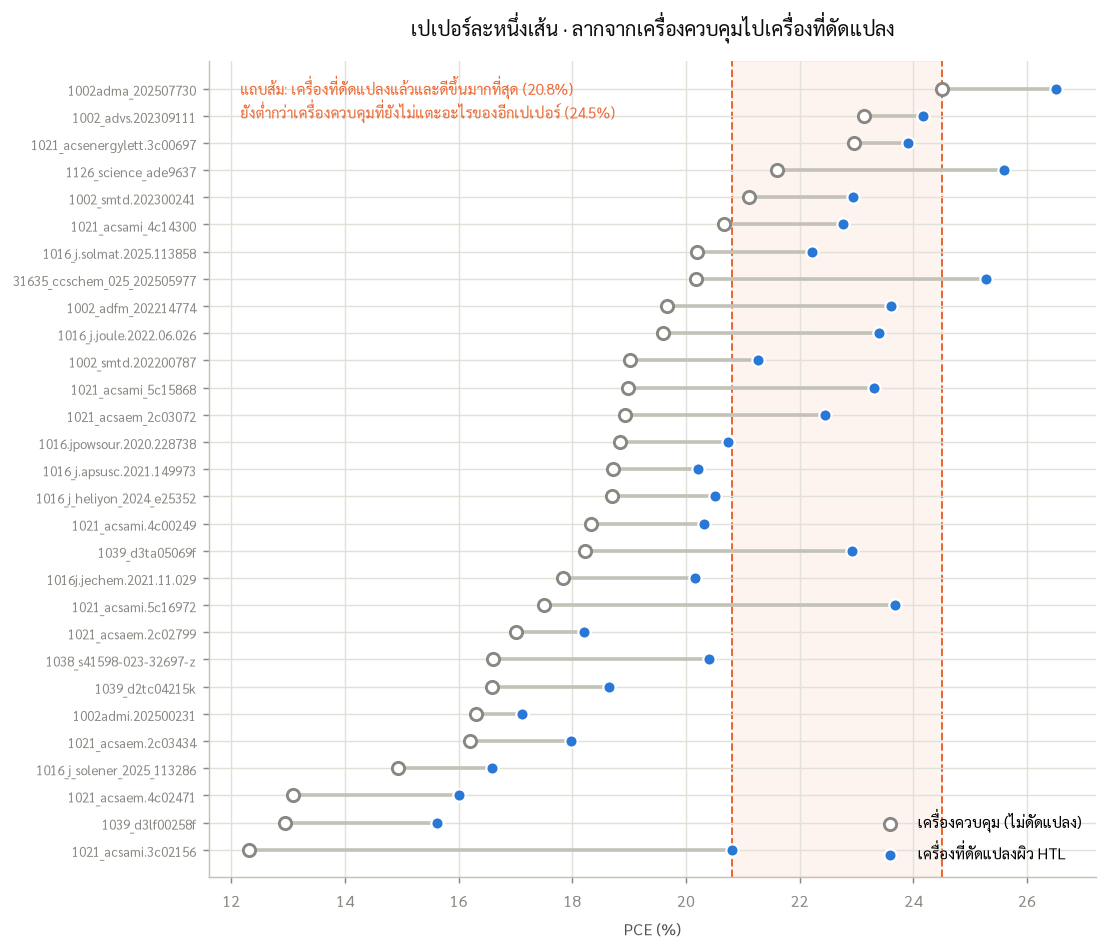

เปเปอร์ที่จับคู่ควบคุม/ดัดแปลงได้ 29 ฉบับ
เครื่องควบคุมของแต่ละเปเปอร์อยู่ระหว่าง 12.31% ถึง 24.50% (กว้าง 12.2 จุด · sd 2.93)
ส่วนผลของการดัดแปลงเองอยู่ระหว่าง 0.80 ถึง 8.50 จุด (sd 1.73)

เทียบในเปเปอร์เดียวกัน  : เครื่องที่ดัดแปลงชนะ 29/29 = 100%
เทียบข้ามเปเปอร์        : เครื่องที่ดัดแปลงของเปเปอร์หนึ่ง ชนะเครื่องควบคุมของอีกเปเปอร์เพียง 74%
  -> ใน 26% ของคู่ การอ่านเลขดิบข้ามเปเปอร์จะสรุปกลับทิศ ว่า 'ไม่ดัดแปลงดีกว่าดัดแปลง'


In [2]:
g = P.groupby("paper")["is_mod"].agg(["sum", "count"])
paired = g[(g["sum"] > 0) & (g["sum"] < g["count"])].index          # เปเปอร์ที่มีทั้งสองฝั่ง

ctrl = P[P["paper"].isin(paired) & ~P["is_mod"]].groupby("paper")["pce"].mean()
best = P[P["paper"].isin(paired) & P["is_mod"]].groupby("paper")["pce"].max()
T = pd.DataFrame({"ctrl": ctrl, "mod": best}).dropna().sort_values("ctrl")
T["delta"] = T["mod"] - T["ctrl"]

fig, ax = plt.subplots(figsize=(8.6, 7.4))
ys = np.arange(len(T))
ax.hlines(ys, T["ctrl"], T["mod"], color=BASE, lw=2, zorder=1)
ax.scatter(T["ctrl"], ys, s=46, color="white", edgecolor=MUTED, lw=1.6, zorder=3,
           label="เครื่องควบคุม (ไม่ดัดแปลง)")
ax.scatter(T["mod"], ys, s=46, color=IN_PAPER, edgecolor="white", lw=1.2, zorder=3,
           label="เครื่องที่ดัดแปลงผิว HTL")
ax.set_yticks(ys, [LBL[p] for p in T.index], fontsize=7.4)
ax.set_ylim(-1, len(T))
ax.set_xlabel("PCE (%)")
ax.set_title("เปเปอร์ละหนึ่งเส้น · ลากจากเครื่องควบคุมไปเครื่องที่ดัดแปลง", pad=14)
ax.legend(loc="lower right", fontsize=8.6)

# เน้นข้อขัดแย้ง: เปเปอร์ที่ดีขึ้นมากที่สุด ยังจบต่ำกว่าเครื่องที่ยังไม่แตะของอีกเปเปอร์
win = T["delta"].idxmax()
hi = T["ctrl"].idxmax()
ax.axvline(T.loc[win, "mod"], color=CROSS, lw=1.1, ls="--", zorder=0)
ax.axvline(T.loc[hi, "ctrl"], color=CROSS, lw=1.1, ls="--", zorder=0)
ax.axvspan(T.loc[win, "mod"], T.loc[hi, "ctrl"], color=CROSS, alpha=0.07, zorder=0)
ax.annotate(f"แถบส้ม: เครื่องที่ดัดแปลงแล้วและดีขึ้นมากที่สุด ({T.loc[win, 'mod']:.1f}%)\n"
            f"ยังต่ำกว่าเครื่องควบคุมที่ยังไม่แตะอะไรของอีกเปเปอร์ ({T.loc[hi, 'ctrl']:.1f}%)",
            xy=(T["ctrl"].min() - 0.15, len(T) - 1.4),
            ha="left", va="center", fontsize=8.2, color=CROSS)
plt.tight_layout(); plt.show()

M, Cc = T["mod"].to_numpy()[:, None], T["ctrl"].to_numpy()[None, :]
off = ~np.eye(len(T), dtype=bool)
print(f"เปเปอร์ที่จับคู่ควบคุม/ดัดแปลงได้ {len(T)} ฉบับ")
print(f"เครื่องควบคุมของแต่ละเปเปอร์อยู่ระหว่าง {T['ctrl'].min():.2f}% ถึง {T['ctrl'].max():.2f}% "
      f"(กว้าง {T['ctrl'].max() - T['ctrl'].min():.1f} จุด · sd {T['ctrl'].std():.2f})")
print(f"ส่วนผลของการดัดแปลงเองอยู่ระหว่าง {T['delta'].min():.2f} ถึง {T['delta'].max():.2f} จุด "
      f"(sd {T['delta'].std():.2f})")
print()
print(f"เทียบในเปเปอร์เดียวกัน  : เครื่องที่ดัดแปลงชนะ {int((T['delta'] > 0).sum())}/{len(T)} "
      f"= {100 * (T['delta'] > 0).mean():.0f}%")
print(f"เทียบข้ามเปเปอร์        : เครื่องที่ดัดแปลงของเปเปอร์หนึ่ง ชนะเครื่องควบคุมของอีกเปเปอร์เพียง "
      f"{100 * (M > Cc)[off].mean():.0f}%")
print(f"  -> ใน {100 * (M < Cc)[off].mean():.0f}% ของคู่ การอ่านเลขดิบข้ามเปเปอร์จะสรุปกลับทิศ "
      f"ว่า 'ไม่ดัดแปลงดีกว่าดัดแปลง'")

**อ่านรูปนี้ยังไง** จุดขาวคือเครื่องควบคุม จุดน้ำเงินคือเครื่องที่ดัดแปลงแล้ว
ความยาวเส้นคือ "ผลของการดัดแปลง" ซึ่งเป็นสิ่งที่เราอยากรู้

ประเด็นคือ **ตำแหน่งที่เส้นเริ่ม กระจายกว้างกว่าความยาวของเส้นเองหลายเท่า**
แล็บที่เก่งอยู่แล้วเริ่มที่ 24% แล็บอื่นเริ่มที่ 12% ความต่างตรงนั้นมาจากฝีมือ ห้องแล็บ
ความชื้นในกล่อง ยี่ห้อสารตั้งต้น — ไม่ได้มาจากสิ่งที่เราสนใจ

ผลคือ ถ้าเรียงเลข PCE ดิบจากทุกเปเปอร์มาจัดอันดับ เรากำลังจัดอันดับ *แล็บ* ไม่ใช่ *วิธี*

---
## หลักฐาน 2 — ความแปรปรวนของ PCE ส่วนใหญ่เป็นของ "เปเปอร์ไหน"

วัดตรง ๆ ว่า ถ้ารู้แค่ว่าแถวนี้มาจากเปเปอร์ฉบับไหน (ไม่รู้อย่างอื่นเลย) จะอธิบาย
ความผันผวนของตัวเลขได้กี่เปอร์เซ็นต์ แล้วเทียบกับตัวแปรที่เราสนใจจริง ๆ

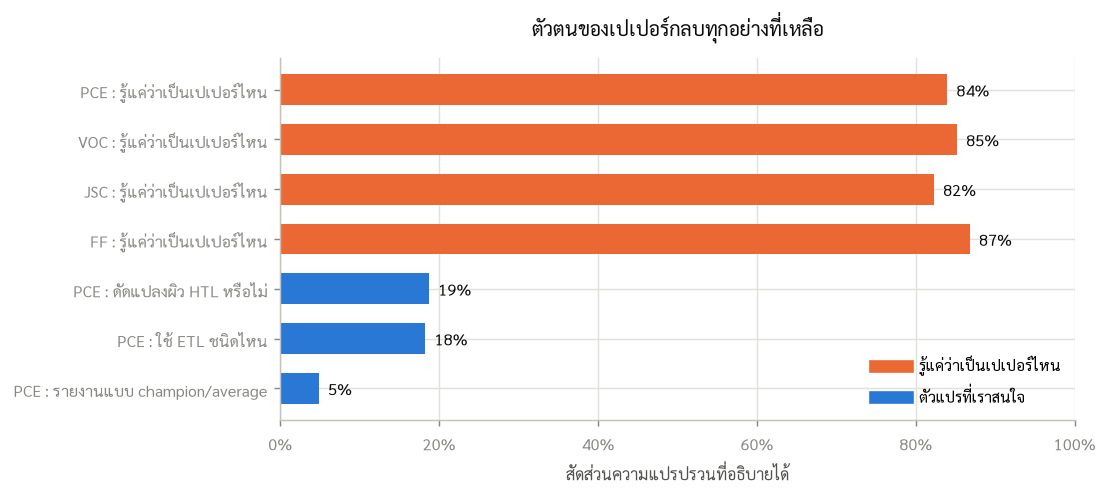

ความแปรปรวนของ PCE ที่อธิบายด้วย 'เปเปอร์ไหน' = 83.9%
เหลือให้ทุกอย่างที่เหลือในโลกอธิบายรวมกัน  = 16.1%

(แท่งแต่ละอันคืออธิบายเดี่ยว ๆ ไม่ได้เอามาบวกกัน — และตัวแปรฝั่งล่างส่วนหนึ่ง
 ก็ซ้อนอยู่ในตัวตนของเปเปอร์อยู่แล้ว เพราะเปเปอร์หนึ่งมักใช้ ETL ชนิดเดียวทั้งฉบับ)


In [3]:
def share(df, col, by):
    """สัดส่วนความแปรปรวนของ col ที่อธิบายได้ด้วยการรู้ค่า by (R² ของค่าเฉลี่ยรายกลุ่ม)"""
    s = df.dropna(subset=[col] if by == "is_mod" else [col, by])
    y = s[col].to_numpy(float)
    gm = s.groupby(by)[col].transform("mean").to_numpy(float)
    return ((gm - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()


left = [(f"{c.upper()} : รู้แค่ว่าเป็นเปเปอร์ไหน", share(P, c, "paper")) for c in ["pce", "voc", "jsc", "ff"]]
right = [("PCE : ดัดแปลงผิว HTL หรือไม่", share(P, "pce", "is_mod")),
         ("PCE : ใช้ ETL ชนิดไหน", share(P, "pce", "etl_family")),
         ("PCE : รายงานแบบ champion/average", share(P, "pce", "jv_variant"))]

fig, ax = plt.subplots(figsize=(8.6, 3.9))
items = left + right
ys = np.arange(len(items))[::-1]
cols = [CROSS] * len(left) + [IN_PAPER] * len(right)
ax.barh(ys, [v for _, v in items], color=cols, height=0.62)
for y, (_, v) in zip(ys, items):
    ax.text(v + 0.012, y, f"{v:.0%}", va="center", fontsize=9, color=INK)
ax.set_yticks(ys, [k for k, _ in items], fontsize=8.8)
ax.set_xlim(0, 1.0)
ax.set_xticks(np.arange(0, 1.01, 0.2), [f"{x:.0%}" for x in np.arange(0, 1.01, 0.2)])
ax.set_xlabel("สัดส่วนความแปรปรวนที่อธิบายได้")
ax.set_title("ตัวตนของเปเปอร์กลบทุกอย่างที่เหลือ", pad=12)
ax.legend(handles=[plt.Line2D([], [], color=CROSS, lw=7, label="รู้แค่ว่าเป็นเปเปอร์ไหน"),
                   plt.Line2D([], [], color=IN_PAPER, lw=7, label="ตัวแปรที่เราสนใจ")],
          loc="lower right", fontsize=8.6)
plt.tight_layout(); plt.show()

print(f"ความแปรปรวนของ PCE ที่อธิบายด้วย 'เปเปอร์ไหน' = {share(P, 'pce', 'paper'):.1%}")
print(f"เหลือให้ทุกอย่างที่เหลือในโลกอธิบายรวมกัน  = {1 - share(P, 'pce', 'paper'):.1%}")
print("\n(แท่งแต่ละอันคืออธิบายเดี่ยว ๆ ไม่ได้เอามาบวกกัน — และตัวแปรฝั่งล่างส่วนหนึ่ง")
print(" ก็ซ้อนอยู่ในตัวตนของเปเปอร์อยู่แล้ว เพราะเปเปอร์หนึ่งมักใช้ ETL ชนิดเดียวทั้งฉบับ)")

**ความหมาย** ตัวเลข ~84% ไม่ได้แปลว่าเปเปอร์ "ทำให้" PCE สูง
แต่แปลว่าสิ่งที่ทำให้เลขต่างกันเกือบทั้งหมด เป็นของที่ติดมากับเปเปอร์เป็นก้อน —
ฝีมือ อุปกรณ์ในแล็บ สูตรที่เขาถนัด วิธีรายงาน

พอเอาข้อมูลมารวมกันแล้วถามว่า "ตัวแปร A ทำให้ PCE สูงขึ้นไหม" คำตอบที่ได้จะเป็น
เสียงสะท้อนของ 84% ก้อนนั้นเป็นหลัก ไม่ใช่ผลของ A

---
## หลักฐาน 3 — ตัวแปรที่ต้องคุมให้เท่ากันก่อนเทียบ ไม่เคยเท่ากันเลย

การเทียบที่ยุติธรรมต้องให้ทุกอย่างเหมือนกันหมด ยกเว้นสิ่งที่เรากำลังทดสอบ
ในเซลล์เพอรอฟสไกต์ ตัวที่ต้องคุมอย่างน้อยคือ

- **`x_Br`** สัดส่วนโบรมีนในสูตร — กระทบ Voc และช่องว่างแถบพลังงานโดยตรง (คุมตัวนี้เป็นอันดับแรก)
- **`a_Cs` / `a_FA`** สัดส่วนซีเซียมและ FA ในสูตร
- **`etl_family`** ชนิดชั้นเก็บอิเล็กตรอน
- **`jv_variant`** วิธีรายงานเลข: เครื่องที่ดีที่สุด (champion) หรือค่าเฉลี่ย — คนละนิยามกัน

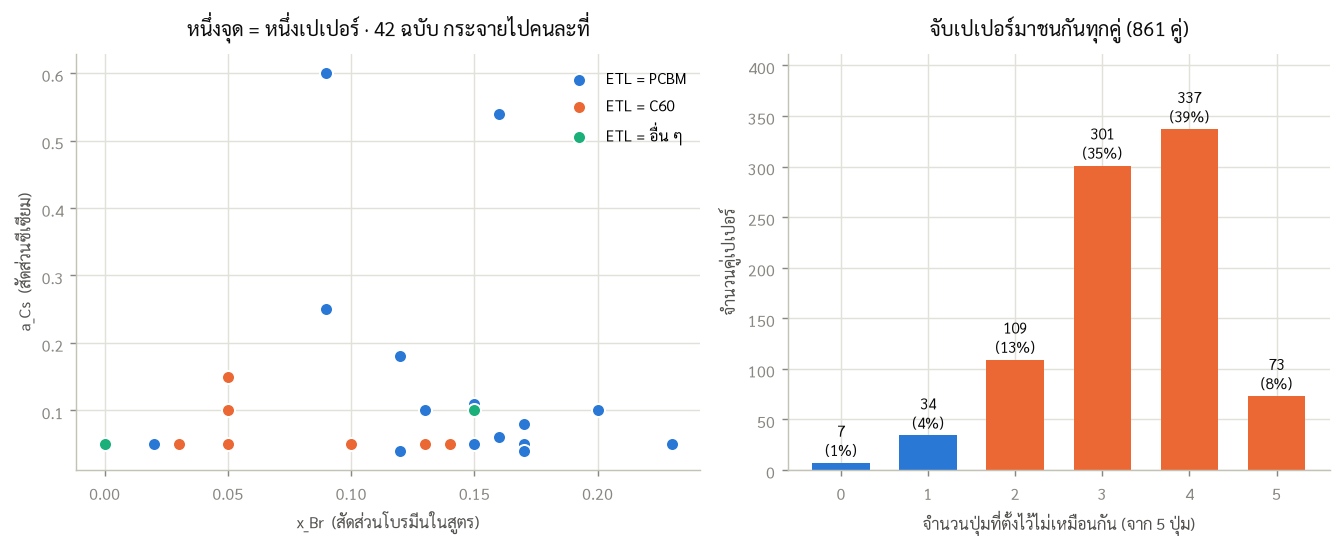

เปเปอร์ที่ระบุครบทั้ง 5 ปุ่ม: 42 ฉบับ · ตั้งค่าไม่ซ้ำกัน 37 แบบ
กลุ่มใหญ่ที่สุดที่ตั้งค่าเหมือนกันเป๊ะ: 3 ฉบับ
คู่เปเปอร์ที่ตั้งค่าเหมือนกันทั้ง 5 ปุ่ม: 7/861 = 0.8%
คู่เปเปอร์ที่ต่างกันตั้งแต่ 3 ปุ่มขึ้นไป : 82.6%
เฉพาะ x_Br อย่างเดียว ต่างกันใน 91.3% ของคู่


In [4]:
KNOBS = ["x_Br", "a_Cs", "a_FA", "etl_family", "jv_variant"]
pk = (P.groupby("paper")[KNOBS]
        .agg(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)
        .dropna())
pkr = pk.round({"x_Br": 2, "a_Cs": 2, "a_FA": 2})

A = pkr.to_numpy(object)
n = len(A)
ndiff = np.array([[(A[i] != A[j]).sum() for j in range(n)] for i in range(n)])
iu = np.triu_indices(n, 1)
dv = ndiff[iu]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})

fam = pkr["etl_family"].where(pkr["etl_family"].isin(["PCBM", "C60"]), "อื่น ๆ")
for name, col in [("PCBM", IN_PAPER), ("C60", CROSS), ("อื่น ๆ", THIRD)]:
    s = pkr[fam == name]
    ax1.scatter(s["x_Br"], s["a_Cs"], s=52, color=col, edgecolor="white", lw=1.1, label=f"ETL = {name}")
ax1.set_xlabel("x_Br  (สัดส่วนโบรมีนในสูตร)")
ax1.set_ylabel("a_Cs  (สัดส่วนซีเซียม)")
ax1.set_title(f"หนึ่งจุด = หนึ่งเปเปอร์ · {n} ฉบับ กระจายไปคนละที่", pad=10)
ax1.legend(fontsize=8.4, loc="upper right")

cnt = pd.Series(dv).value_counts().reindex(range(len(KNOBS) + 1), fill_value=0)
ax2.bar(cnt.index, cnt.to_numpy(), color=[IN_PAPER if k <= 1 else CROSS for k in cnt.index], width=0.66)
for k, v in cnt.items():
    if v:
        ax2.text(k, v + max(cnt) * 0.02, f"{v}\n({v / len(dv):.0%})", ha="center", fontsize=8.2, color=INK)
ax2.set_xticks(range(len(KNOBS) + 1))
ax2.set_xlabel("จำนวนปุ่มที่ตั้งไว้ไม่เหมือนกัน (จาก 5 ปุ่ม)")
ax2.set_ylabel("จำนวนคู่เปเปอร์")
ax2.set_ylim(0, max(cnt) * 1.22)
ax2.set_title(f"จับเปเปอร์มาชนกันทุกคู่ ({len(dv)} คู่)", pad=10)
plt.tight_layout(); plt.show()

fp = pkr.astype(str).agg("|".join, axis=1)
xb = pkr["x_Br"].to_numpy()
print(f"เปเปอร์ที่ระบุครบทั้ง 5 ปุ่ม: {n} ฉบับ · ตั้งค่าไม่ซ้ำกัน {fp.nunique()} แบบ")
print(f"กลุ่มใหญ่ที่สุดที่ตั้งค่าเหมือนกันเป๊ะ: {fp.value_counts().iloc[0]} ฉบับ")
print(f"คู่เปเปอร์ที่ตั้งค่าเหมือนกันทั้ง 5 ปุ่ม: {int((dv == 0).sum())}/{len(dv)} = {(dv == 0).mean():.1%}")
print(f"คู่เปเปอร์ที่ต่างกันตั้งแต่ 3 ปุ่มขึ้นไป : {(dv >= 3).mean():.1%}")
print(f"เฉพาะ x_Br อย่างเดียว ต่างกันใน {(xb[:, None] != xb[None, :])[iu].mean():.1%} ของคู่")

**ความหมาย** หยิบสองเปเปอร์มาสุ่ม ๆ โอกาสที่ทั้งคู่ตั้งค่าเหมือนกันครบห้าปุ่มแทบเป็นศูนย์
ส่วนใหญ่ต่างกันสามปุ่มขึ้นไป

พอเห็นว่า PCE ของสองเปเปอร์นี้ต่างกัน เราแยกไม่ออกเลยว่าเป็นเพราะ
วิธีดัดแปลงที่ต่างกัน หรือเพราะโบรมีนไม่เท่ากัน หรือเพราะ ETL คนละชนิด
หรือเพราะฝั่งหนึ่งรายงานเครื่องที่ดีที่สุดส่วนอีกฝั่งรายงานค่าเฉลี่ย — สี่คำอธิบายมาพร้อมกันเสมอ

---
## หลักฐาน 4 — สารดัดแปลงเกือบทุกชนิดอยู่ในเปเปอร์เดียว

นี่คือข้อจำกัดที่แข็งที่สุด ไม่ว่าจะใช้สถิติดีแค่ไหนก็แก้ไม่ได้

ถ้าสาร X ปรากฏในเปเปอร์เดียว คำว่า "ผลของสาร X" กับ "ผลของเปเปอร์ที่ใช้สาร X"
เป็นตัวเลขตัวเดียวกันในข้อมูล ไม่มีวิธีทางสถิติใดแยกสองอย่างนี้ออกจากกันได้

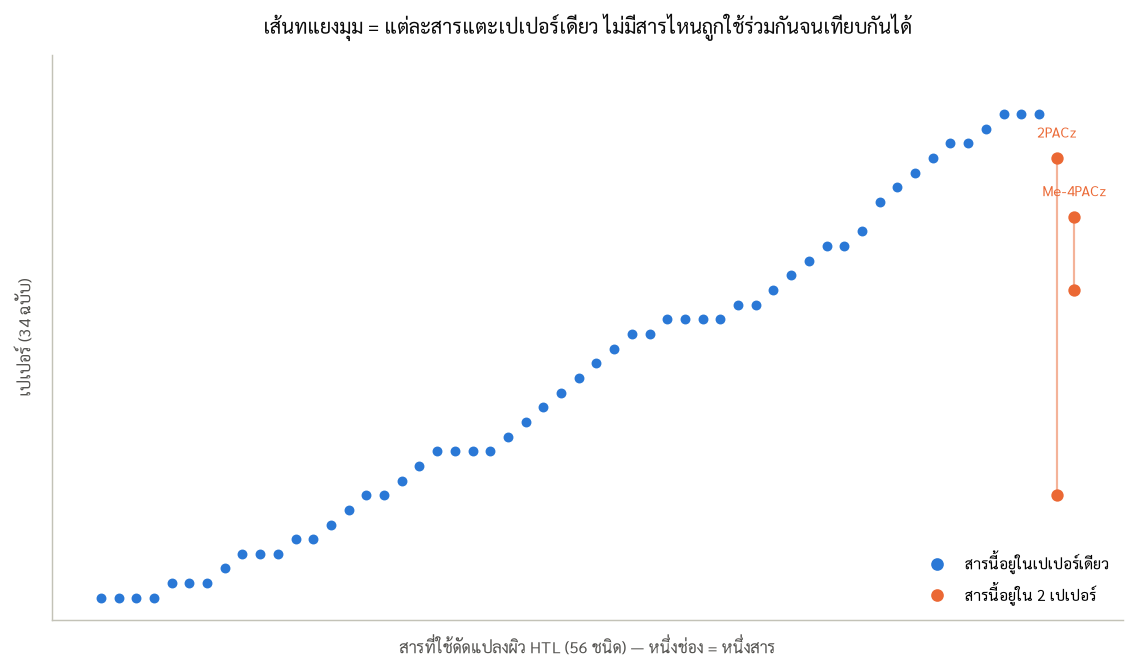

สารดัดแปลงผิว HTL ที่ระบุชื่อได้ 56 ชนิด จากอุปกรณ์ 68 ตัว
อยู่ในเปเปอร์เดียว 54 ชนิด = 96%
อยู่ใน 2 เปเปอร์   2 ชนิด -> ['Me-4PACz', '2PACz']

จำนวนอุปกรณ์เฉลี่ยต่อสารหนึ่งชนิด = 1.2 ตัว
ถ้าจะถามว่า 'สารไหนดีที่สุด' ก็คือถามจากกลุ่มตัวอย่างขนาดประมาณหนึ่งเครื่องต่อหนึ่งสาร


In [5]:
mm = P.dropna(subset=["htl_mod_material"])
per_mat = mm.groupby("htl_mod_material")["paper"].nunique().sort_values()
order_p = list(mm.groupby("paper")["pce"].mean().sort_values().index)
pos_p = {p: i for i, p in enumerate(order_p)}
order_m = sorted(per_mat.index,
                 key=lambda m: (per_mat[m] > 1,
                                np.mean([pos_p[p] for p in mm.loc[mm["htl_mod_material"] == m, "paper"].unique()])))
pos_m = {m: i for i, m in enumerate(order_m)}

fig, ax = plt.subplots(figsize=(9.2, 5.4))
for m, gg in mm.groupby("htl_mod_material"):
    reused = per_mat[m] > 1
    papers_here = list(gg["paper"].unique())
    if reused:   # ลากเส้นเชื่อมให้เห็นว่าสารชนิดเดียวกันนี้แตะเปเปอร์มากกว่าหนึ่งฉบับ
        ax.vlines(pos_m[m], min(pos_p[p] for p in papers_here), max(pos_p[p] for p in papers_here),
                  color=CROSS, lw=1.2, alpha=0.5, zorder=1)
    for p in papers_here:
        ax.scatter(pos_m[m], pos_p[p], s=34 if reused else 20,
                   color=CROSS if reused else IN_PAPER, zorder=3 if reused else 2)
    if reused:
        ax.annotate(m, (pos_m[m], max(pos_p[p] for p in papers_here) + 1.4),
                    ha="center", fontsize=8, color=CROSS)
ax.set_xlabel(f"สารที่ใช้ดัดแปลงผิว HTL ({len(per_mat)} ชนิด) — หนึ่งช่อง = หนึ่งสาร", labelpad=8)
ax.set_ylabel(f"เปเปอร์ ({mm['paper'].nunique()} ฉบับ)", labelpad=10)
ax.set_xticks([]); ax.set_yticks([])
ax.set_ylim(-1.5, len(order_p) + 3.0)
ax.set_title("เส้นทแยงมุม = แต่ละสารแตะเปเปอร์เดียว ไม่มีสารไหนถูกใช้ร่วมกันจนเทียบกันได้", pad=12)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=IN_PAPER, label="สารนี้อยู่ในเปเปอร์เดียว"),
                   plt.Line2D([], [], marker="o", ls="", color=CROSS, label="สารนี้อยู่ใน 2 เปเปอร์")],
          loc="lower right", fontsize=8.6)
plt.tight_layout()
plt.subplots_adjust(left=0.09, bottom=0.11)
plt.show()

print(f"สารดัดแปลงผิว HTL ที่ระบุชื่อได้ {len(per_mat)} ชนิด จากอุปกรณ์ {len(mm)} ตัว")
print(f"อยู่ในเปเปอร์เดียว {int((per_mat == 1).sum())} ชนิด = {(per_mat == 1).mean():.0%}")
print(f"อยู่ใน 2 เปเปอร์   {int((per_mat == 2).sum())} ชนิด -> {list(per_mat[per_mat == 2].index)}")
print(f"\nจำนวนอุปกรณ์เฉลี่ยต่อสารหนึ่งชนิด = {len(mm) / len(per_mat):.1f} ตัว")
print("ถ้าจะถามว่า 'สารไหนดีที่สุด' ก็คือถามจากกลุ่มตัวอย่างขนาดประมาณหนึ่งเครื่องต่อหนึ่งสาร")

**ความหมาย (ภาษาสถิติเรียกว่า *confounding* แบบสมบูรณ์)**
ลองนึกว่าอยากรู้ว่าปุ๋ยยี่ห้อไหนดีกว่ากัน แต่ยี่ห้อ A ใช้ในสวนหนึ่งเท่านั้น
ยี่ห้อ B ใช้ในอีกสวนหนึ่งเท่านั้น ถ้าสวน A ได้ผลดีกว่า เราไม่มีทางรู้ว่าเป็นเพราะปุ๋ย
หรือเพราะดินในสวน A ดีกว่าอยู่แล้ว — ต้องมีอย่างน้อยหนึ่งสวนที่ลองทั้งสองยี่ห้อ

ข้อมูลชุดนี้ไม่มี "สวนที่ลองทั้งสองยี่ห้อ" เลยสำหรับสารเกือบทั้งหมด

---
## หลักฐาน 5 — ทิศของความสัมพันธ์พลิกกลับ เมื่อเปลี่ยนมุมมอง

ทดสอบสองแบบกับตัวเลขชุดเดียวกัน

- **ข้ามเปเปอร์** เทกองข้อมูลทุกแถวรวมกัน แล้วหาความสัมพันธ์กับ PCE
- **ในเปเปอร์** ลบค่าเฉลี่ยของเปเปอร์ตัวเองออกก่อน (คือถามว่า *ภายในแล็บเดียวกัน*
  เครื่องที่ค่านี้สูงกว่า มี PCE สูงกว่าไหม) แล้วค่อยหาความสัมพันธ์

ถ้าข้อมูลรวมกันได้จริง สองวิธีควรให้คำตอบทิศเดียวกัน

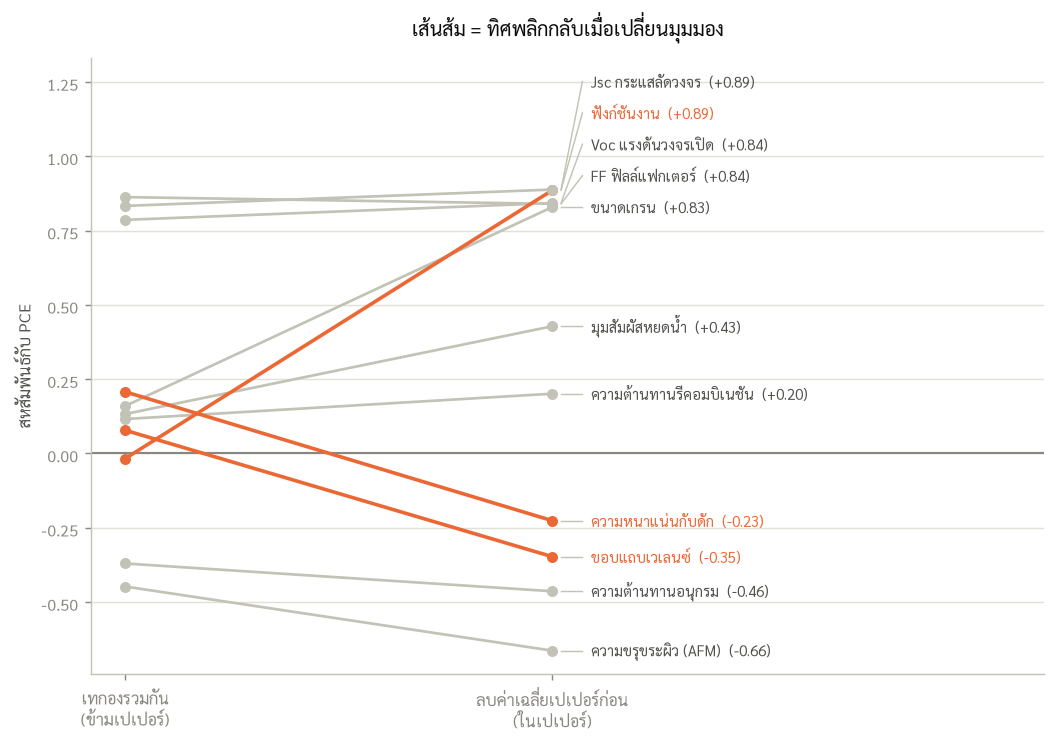

ตัวแปรที่ทดสอบได้ 11 ตัว · ทิศพลิกกลับ 3 ตัว
  ขอบแถบเวเลนซ์          ข้ามเปเปอร์ +0.08 (ยิ่งสูง PCE ยิ่งสูง) -> ในเปเปอร์ -0.35 (ยิ่งสูง PCE ยิ่งต่ำ)   [48 เครื่อง · 20 เปเปอร์]
  ความหนาแน่นกับดัก      ข้ามเปเปอร์ +0.21 (ยิ่งสูง PCE ยิ่งสูง) -> ในเปเปอร์ -0.23 (ยิ่งสูง PCE ยิ่งต่ำ)   [52 เครื่อง · 20 เปเปอร์]
  ฟังก์ชันงาน            ข้ามเปเปอร์ -0.02 (ยิ่งสูง PCE ยิ่งต่ำ) -> ในเปเปอร์ +0.89 (ยิ่งสูง PCE ยิ่งสูง)   [23 เครื่อง · 11 เปเปอร์]

หมายเหตุ: คอลัมน์ grain_size ในตาราง target ยังปนค่าจากผิวบน/หน้าตัด/ไม่ระบุอยู่
ตามมติให้ใช้เฉพาะค่าจากผิวบน ตัวเลขแถวนั้นจึงยังเป็นค่าชั่วคราว


In [6]:
FEATS = ["voc", "jsc", "ff", "grain_size", "contact_angle", "afm_rms",
         "trap_density", "rs", "rrec", "vbm", "work_function", "x_Br", "psk_anneal_C"]
NICE = {"voc": "Voc แรงดันวงจรเปิด", "jsc": "Jsc กระแสลัดวงจร", "ff": "FF ฟิลล์แฟกเตอร์",
        "grain_size": "ขนาดเกรน", "contact_angle": "มุมสัมผัสหยดน้ำ", "afm_rms": "ความขรุขระผิว (AFM)",
        "trap_density": "ความหนาแน่นกับดัก", "rs": "ความต้านทานอนุกรม", "rrec": "ความต้านทานรีคอมบิเนชัน",
        "vbm": "ขอบแถบเวเลนซ์", "work_function": "ฟังก์ชันงาน", "x_Br": "สัดส่วนโบรมีน",
        "psk_anneal_C": "อุณหภูมิอบฟิล์ม"}

rows = []
for f in FEATS:
    s = P.dropna(subset=[f, "pce"])
    if len(s) < 10:
        continue
    naive = np.corrcoef(s[f], s["pce"])[0, 1]
    parts = [pd.DataFrame({"x": gg[f] - gg[f].mean(), "y": gg["pce"] - gg["pce"].mean()})
             for _, gg in s.groupby("paper") if len(gg) >= 2 and gg[f].nunique() > 1]
    if not parts:
        continue
    w = pd.concat(parts)
    rows.append((f, naive, np.corrcoef(w["x"], w["y"])[0, 1], len(s), s["paper"].nunique(), len(parts)))

R = pd.DataFrame(rows, columns=["f", "naive", "within", "n", "papers", "papers_within"])
R["flip"] = np.sign(R["naive"]) != np.sign(R["within"])
R = R.sort_values("within")

# กันป้ายชื่อทับกัน: ดันป้ายที่ชนกันให้ห่างอย่างน้อย gap แล้วลากเส้นบาง ๆ กลับไปหาจุดจริง
yv = R["within"].to_numpy(float)
gap = (yv.max() - yv.min()) * 0.068
lab = yv.copy()
for i in range(1, len(lab)):
    lab[i] = max(lab[i], lab[i - 1] + gap)

fig, ax = plt.subplots(figsize=(8.2, 5.8))
for i, r in enumerate(R.itertuples()):
    col, lw = (CROSS, 2.0) if r.flip else (BASE, 1.5)
    ax.plot([0, 1], [r.naive, r.within], color=col, lw=lw, zorder=3 if r.flip else 2)
    ax.scatter([0, 1], [r.naive, r.within], s=26, color=col, zorder=4)
    ax.plot([1.02, 1.07], [r.within, lab[i]], color=BASE, lw=0.8, zorder=2)
    ax.annotate(f"{NICE[r.f]}  ({r.within:+.2f})", (1.09, lab[i]), va="center", fontsize=8.2,
                color=CROSS if r.flip else INK2)
ax.axhline(0, color=MUTED, lw=1.2, zorder=1)
ax.set_xlim(-0.08, 2.15)
ax.set_ylim(min(yv.min(), R["naive"].min(), lab.min()) - 0.08,
            max(yv.max(), R["naive"].max(), lab.max()) + 0.08)
ax.set_xticks([0, 1], ["เทกองรวมกัน\n(ข้ามเปเปอร์)", "ลบค่าเฉลี่ยเปเปอร์ก่อน\n(ในเปเปอร์)"], fontsize=9)
ax.set_ylabel("สหสัมพันธ์กับ PCE")
ax.set_title("เส้นส้ม = ทิศพลิกกลับเมื่อเปลี่ยนมุมมอง", pad=12)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print(f"ตัวแปรที่ทดสอบได้ {len(R)} ตัว · ทิศพลิกกลับ {int(R['flip'].sum())} ตัว")
for r in R[R["flip"]].itertuples():
    d1 = "ยิ่งสูง PCE ยิ่งสูง" if r.naive > 0 else "ยิ่งสูง PCE ยิ่งต่ำ"
    d2 = "ยิ่งสูง PCE ยิ่งสูง" if r.within > 0 else "ยิ่งสูง PCE ยิ่งต่ำ"
    print(f"  {NICE[r.f]:22} ข้ามเปเปอร์ {r.naive:+.2f} ({d1}) -> ในเปเปอร์ {r.within:+.2f} ({d2})"
          f"   [{r.n} เครื่อง · {r.papers} เปเปอร์]")
print("\nหมายเหตุ: คอลัมน์ grain_size ในตาราง target ยังปนค่าจากผิวบน/หน้าตัด/ไม่ระบุอยู่")
print("ตามมติให้ใช้เฉพาะค่าจากผิวบน ตัวเลขแถวนั้นจึงยังเป็นค่าชั่วคราว")

**ความหมาย** ปรากฏการณ์นี้มีชื่อว่า **Simpson's paradox** ความสัมพันธ์ที่เห็นในกองข้อมูลรวม
อาจตรงข้ามกับความสัมพันธ์จริงในทุก ๆ กลุ่มย่อย

ตัวอย่างในชีวิตจริง: ถ้าดูข้อมูลรวมจะพบว่า "โรงพยาบาลที่มีเครื่องมือดี มีอัตราตายสูงกว่า"
ซึ่งไม่ได้แปลว่าเครื่องมือดีฆ่าคน แต่เพราะคนไข้หนักถูกส่งไปที่นั่น พอแยกดูทีละระดับความหนัก
ทิศก็กลับด้านทันที — ตรงนี้ "เปเปอร์" ทำหน้าที่เหมือน "โรงพยาบาล"

ผลสำหรับงานเรา: **ค่าสหสัมพันธ์ที่คำนวณจากข้อมูลรวมทุกเปเปอร์ เชื่อไม่ได้เลย**
ต้องวัดภายในเปเปอร์เท่านั้น

---
## หลักฐาน 6 — แบบจำลองที่ดูแม่น จริง ๆ แค่จำได้ว่ามาจากเปเปอร์ไหน

ลองฝึกแบบจำลอง (ridge regression) ทำนาย PCE จากสูตรเคมี ชนิด ETL และเงื่อนไขกระบวนการ
แล้ววัดผลสองวิธี

1. **สุ่มแบ่ง 5 ส่วน** — วิธีมาตรฐาน แต่เครื่องจากเปเปอร์เดียวกันจะกระจายไปทั้งฝั่งฝึกและฝั่งทดสอบ
2. **กันทั้งเปเปอร์ออก** — เอาเปเปอร์หนึ่งออกทั้งฉบับ ฝึกจากที่เหลือ แล้วทายเปเปอร์นั้น
   คือสถานการณ์จริงที่เราอยากใช้งาน: *"มีเปเปอร์ใหม่มา ทายให้หน่อย"*

และใส่ตัวเปรียบเทียบสำคัญ: แบบจำลองที่ **ไม่รู้อะไรเลยนอกจากว่าแถวนี้มาจากเปเปอร์ไหน**
แล้วทายด้วยค่าเฉลี่ยของเปเปอร์นั้น

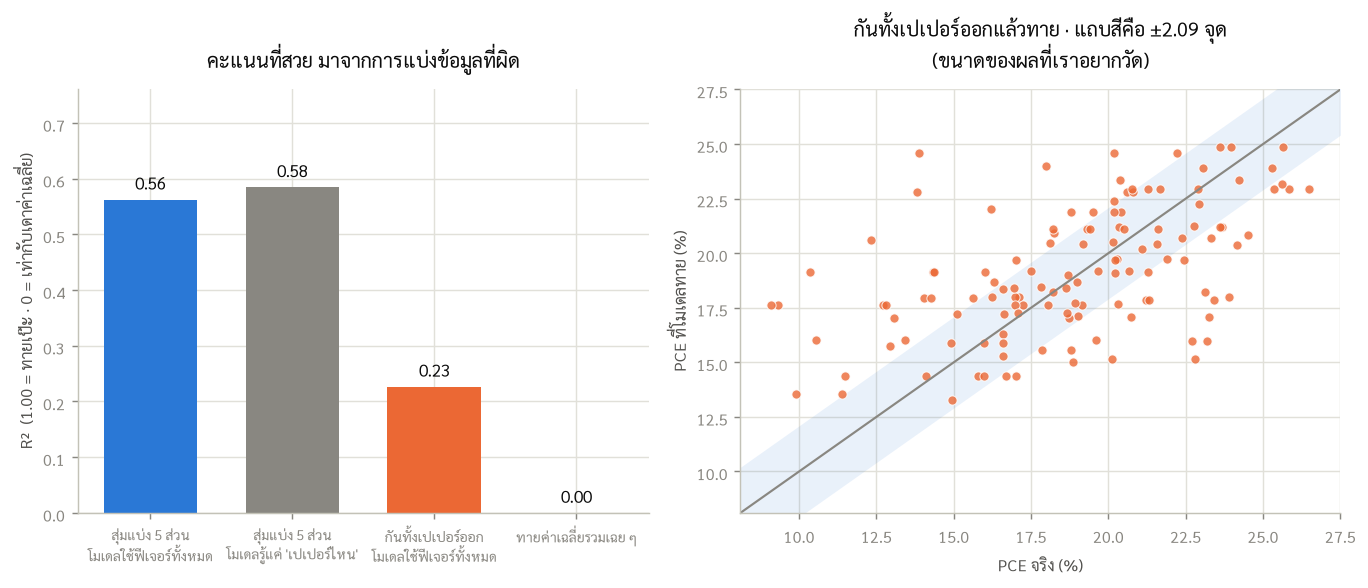

สุ่มแบ่ง 5 ส่วน  โมเดลใช้ฟีเจอร์            R² = 0.563
สุ่มแบ่ง 5 ส่วน  โมเดลรู้แค่ 'เปเปอร์ไหน'   R² = 0.585  <- สูงกว่า
กันทั้งเปเปอร์ออก โมเดลใช้ฟีเจอร์           R² = 0.227

พลาดเฉลี่ย (MAE) ตอนกันเปเปอร์ออก = 2.63 จุด
เทียบกับเดาค่าเฉลี่ยรวมเฉย ๆ        = 3.13 จุด
เทียบกับขนาดของผลที่อยากวัด        = 2.09 จุด  <- ความพลาดใหญ่กว่าสิ่งที่จะวัด
อุปกรณ์ที่โมเดลทายพลาดเกิน 2.09 จุด: 53% ของทั้งหมด (จุดที่หลุดนอกแถบสี)

เปเปอร์ที่โมเดลทายพลาดเกิน 2 จุด: 18/43 ฉบับ
                            PCE จริงเฉลี่ย  โมเดลทาย  พลาด
paper                                                     
1007_s10854-017-8094-9               10.98     17.62  6.64
1021_acsenergylett.3c00697           23.27     16.65 -6.61
1002_solr_202200422                  21.46     15.15 -6.31
1002_solr.202500173                  23.25     17.09 -6.16
1021_acsaem.2c03434                  17.09     22.99  5.90


In [7]:
NUMS = ["x_Br", "a_Cs", "a_FA", "psk_spin_rpm", "psk_anneal_C", "psk_anneal_time_s",
        "antisolvent_vol_uL", "htl_anneal_C", "n_coating_layers"]
BINS = ["is_mod", "coat_htl", "coat_psk", "coat_etl"]

X = pd.concat([P[NUMS].astype(float), P[BINS].astype(float),
               pd.get_dummies(P["etl_family"], prefix="etl", dtype=float)], axis=1)
X = X.fillna(X.median(numeric_only=True))
Xv, y, grp = X.to_numpy(float), P["pce"].to_numpy(float), P["paper"].to_numpy()


def ridge_pred(Xtr, ytr, Xte, lam=1.0):
    mu, sd = Xtr.mean(0), Xtr.std(0)
    sd = np.where(sd == 0, 1, sd)
    A, B, ym = (Xtr - mu) / sd, (Xte - mu) / sd, ytr.mean()
    w = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (ytr - ym))
    return B @ w + ym


def r2(a, b):
    return 1 - ((a - b) ** 2).sum() / ((a - a.mean()) ** 2).sum()


def cv_random(seed, k=5):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    pf, pm = np.empty(len(y)), np.empty(len(y))
    for f in np.array_split(idx, k):
        tr = np.setdiff1d(idx, f)
        pf[f] = ridge_pred(Xv[tr], y[tr], Xv[f])
        mean_by = pd.Series(y[tr]).groupby(pd.Series(grp[tr])).mean()     # รู้แค่ว่าเป็นเปเปอร์ไหน
        pm[f] = [mean_by.get(gname, y[tr].mean()) for gname in grp[f]]
    return r2(y, pf), r2(y, pm)


runs = [cv_random(s) for s in range(30)]
r_rand_feat = float(np.mean([a for a, _ in runs]))
r_rand_paper = float(np.mean([b for _, b in runs]))

p_lopo = np.empty(len(y))
for gname in np.unique(grp):
    te, tr = np.where(grp == gname)[0], np.where(grp != gname)[0]
    p_lopo[te] = ridge_pred(Xv[tr], y[tr], Xv[te])
r_lopo = r2(y, p_lopo)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.6, 4.6), gridspec_kw={"width_ratios": [1, 1.05]})

bars = [("สุ่มแบ่ง 5 ส่วน\nโมเดลใช้ฟีเจอร์ทั้งหมด", r_rand_feat, IN_PAPER),
        ("สุ่มแบ่ง 5 ส่วน\nโมเดลรู้แค่ 'เปเปอร์ไหน'", r_rand_paper, MUTED),
        ("กันทั้งเปเปอร์ออก\nโมเดลใช้ฟีเจอร์ทั้งหมด", r_lopo, CROSS),
        ("ทายค่าเฉลี่ยรวมเฉย ๆ", 0.0, BASE)]
ax1.bar(range(4), [v for _, v, _ in bars], color=[c for _, _, c in bars], width=0.66)
for i, (_, v, _) in enumerate(bars):
    ax1.text(i, v + 0.018, f"{v:.2f}", ha="center", fontsize=9.4, color=INK)
ax1.set_xticks(range(4), [k for k, _, _ in bars], fontsize=7.6)
ax1.set_ylabel("R²  (1.00 = ทายเป๊ะ · 0 = เท่ากับเดาค่าเฉลี่ย)")
ax1.set_ylim(0, max(r_rand_feat, r_rand_paper) * 1.30)
ax1.set_title("คะแนนที่สวย มาจากการแบ่งข้อมูลที่ผิด", pad=12)

band = float(T["delta"].median())
lo, hi = min(y.min(), p_lopo.min()) - 1, max(y.max(), p_lopo.max()) + 1
ax2.fill_between([lo, hi], [lo - band, hi - band], [lo + band, hi + band],
                 color=IN_PAPER, alpha=0.10, lw=0)
ax2.plot([lo, hi], [lo, hi], color=MUTED, lw=1.2)
ax2.scatter(y, p_lopo, s=26, color=CROSS, alpha=0.8, edgecolor="white", lw=0.6)
ax2.set_xlim(lo, hi); ax2.set_ylim(lo, hi)
ax2.set_xlabel("PCE จริง (%)"); ax2.set_ylabel("PCE ที่โมเดลทาย (%)")
ax2.set_title(f"กันทั้งเปเปอร์ออกแล้วทาย · แถบสีคือ ±{band:.2f} จุด\n(ขนาดของผลที่เราอยากวัด)", pad=12)
plt.tight_layout(); plt.show()

err = np.abs(y - p_lopo)
ep = pd.DataFrame({"paper": grp, "y": y, "pred": p_lopo}).groupby("paper").mean(numeric_only=True)
ep["พลาด"] = ep["pred"] - ep["y"]
print(f"สุ่มแบ่ง 5 ส่วน  โมเดลใช้ฟีเจอร์            R² = {r_rand_feat:.3f}")
print(f"สุ่มแบ่ง 5 ส่วน  โมเดลรู้แค่ 'เปเปอร์ไหน'   R² = {r_rand_paper:.3f}  <- สูงกว่า")
print(f"กันทั้งเปเปอร์ออก โมเดลใช้ฟีเจอร์           R² = {r_lopo:.3f}")
print(f"\nพลาดเฉลี่ย (MAE) ตอนกันเปเปอร์ออก = {err.mean():.2f} จุด")
print(f"เทียบกับเดาค่าเฉลี่ยรวมเฉย ๆ        = {np.abs(y - y.mean()).mean():.2f} จุด")
print(f"เทียบกับขนาดของผลที่อยากวัด        = {band:.2f} จุด  <- ความพลาดใหญ่กว่าสิ่งที่จะวัด")
print(f"อุปกรณ์ที่โมเดลทายพลาดเกิน {band:.2f} จุด: {(err > band).mean():.0%} ของทั้งหมด (จุดที่หลุดนอกแถบสี)")
print(f"\nเปเปอร์ที่โมเดลทายพลาดเกิน 2 จุด: {int((ep['พลาด'].abs() > 2).sum())}/{len(ep)} ฉบับ")
print(ep.reindex(ep["พลาด"].abs().sort_values(ascending=False).index)
        .head(5)[["y", "pred", "พลาด"]]
        .rename(columns={"y": "PCE จริงเฉลี่ย", "pred": "โมเดลทาย"})
        .rename(index=LBL).round(2).to_string())

**อ่านยังไง** แท่งซ้ายสุดดูดี — R² ราวครึ่งหนึ่ง ถ้าหยุดตรงนี้ก็จะสรุปว่า "ฝึกโมเดลได้"

แต่แท่งที่สองคือแบบจำลองที่ **ไม่เห็นฟีเจอร์ใด ๆ เลย** รู้แค่ว่าแถวนี้มาจากเปเปอร์ไหน
แล้วทายด้วยค่าเฉลี่ยของเปเปอร์นั้น — แล้วมันทำคะแนนได้ *เท่ากันหรือดีกว่า*
แปลว่าคะแนนของแท่งแรกไม่ได้มาจากความรู้ทางฟิสิกส์ แต่มาจากการที่เครื่องพี่น้องจากเปเปอร์เดียวกัน
รั่วไปอยู่ฝั่งฝึก โมเดลแค่จำค่าเฉลี่ยของเปเปอร์นั้นได้

พอกันทั้งเปเปอร์ออก (แท่งสาม) — สถานการณ์จริงที่เราอยากใช้ — คะแนนตกลงทันที
และที่สำคัญกว่าคะแนน: **ความพลาดเฉลี่ยใหญ่กว่าขนาดของผลที่เราต้องการวัด**
เครื่องมือที่พลาดมากกว่าสิ่งที่จะวัด ใช้ตัดสินใจไม่ได้

---
## หลักฐาน 7 — ตัวชี้วัดกลไกมีไม่พร้อมกัน ไม่มีบล็อกข้อมูลร่วม

สมมติยอมแพ้เรื่องทำนาย PCE แล้วหันมาถามเรื่องกลไกแทน เช่น
*"การดัดแปลงช่วยเพราะทำให้เกรนโตขึ้น หรือเพราะลดกับดักประจุ"*
คำถามแบบนี้ต้องการเปเปอร์ที่วัดหลายอย่างพร้อมกัน — ลองดูว่ามีไหม

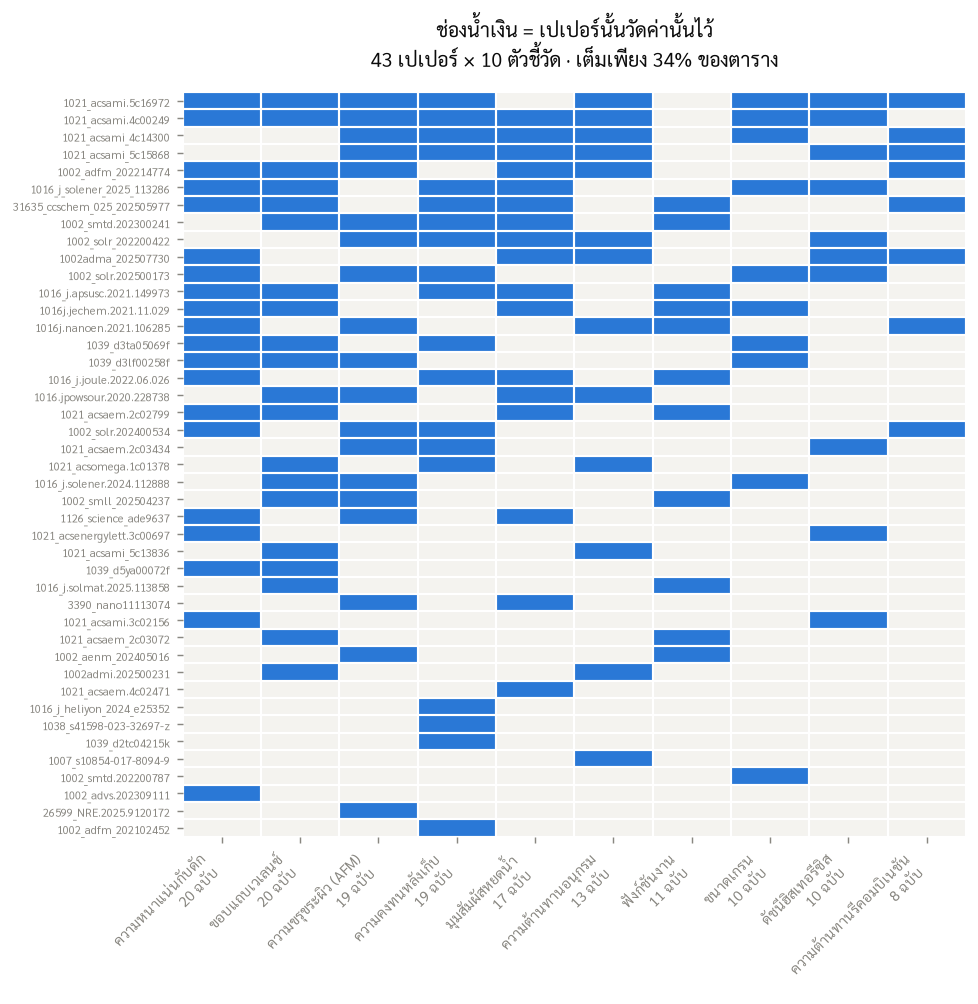

ตัวชี้วัดต่อเปเปอร์: มัธยฐาน 3 จาก 10 อย่าง
เปเปอร์ที่วัดครบทั้ง 10 อย่าง: 0 ฉบับ

ชุดตัวชี้วัดที่หาเปเปอร์ซึ่งวัดครบพร้อมกันได้มากที่สุด
  2 ตัวชี้วัดพร้อมกัน -> มีแค่ 11 เปเปอร์   (ความหนาแน่นกับดัก, ขอบแถบเวเลนซ์)
  3 ตัวชี้วัดพร้อมกัน -> มีแค่ 7 เปเปอร์   (ความหนาแน่นกับดัก, ขอบแถบเวเลนซ์, มุมสัมผัสหยดน้ำ)
  4 ตัวชี้วัดพร้อมกัน -> มีแค่ 4 เปเปอร์   (ความหนาแน่นกับดัก, ขอบแถบเวเลนซ์, ความคงทนหลังเก็บ, มุมสัมผัสหยดน้ำ)
  5 ตัวชี้วัดพร้อมกัน -> มีแค่ 3 เปเปอร์   (ความหนาแน่นกับดัก, ขอบแถบเวเลนซ์, ความคงทนหลังเก็บ, ขนาดเกรน, ดัชนีฮิสเทอรีซิส)
  6 ตัวชี้วัดพร้อมกัน -> มีแค่ 2 เปเปอร์   (ความหนาแน่นกับดัก, ขอบแถบเวเลนซ์, ความขรุขระผิว (AFM), ความคงทนหลังเก็บ, ความต้านทานอนุกรม, ขนาดเกรน)


In [8]:
MEAS = ["trap_density", "vbm", "afm_rms", "retention_25c", "contact_angle",
        "rs", "work_function", "grain_size", "hi", "rrec"]
MNAME = {"trap_density": "ความหนาแน่นกับดัก", "vbm": "ขอบแถบเวเลนซ์", "afm_rms": "ความขรุขระผิว (AFM)",
         "retention_25c": "ความคงทนหลังเก็บ", "contact_angle": "มุมสัมผัสหยดน้ำ",
         "rs": "ความต้านทานอนุกรม", "work_function": "ฟังก์ชันงาน", "grain_size": "ขนาดเกรน",
         "hi": "ดัชนีฮิสเทอรีซิส", "rrec": "ความต้านทานรีคอมบิเนชัน"}

M = P.groupby("paper")[MEAS].apply(lambda gg: gg.notna().any())
cols = list(M.sum().sort_values(ascending=False).index)
M = M[cols]
M = M.loc[M.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7.6, 7.8))
ax.imshow(M.to_numpy(float), aspect="auto", vmin=0, vmax=1, interpolation="nearest",
          cmap=plt.matplotlib.colors.ListedColormap(["#f4f3ef", IN_PAPER]))
ax.set_xticks(range(len(cols)), [f"{MNAME[c]}\n{int(M[c].sum())} ฉบับ" for c in cols],
              rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(M)), [LBL[p] for p in M.index], fontsize=6.4)
ax.set_title(f"ช่องน้ำเงิน = เปเปอร์นั้นวัดค่านั้นไว้\n{len(M)} เปเปอร์ × {len(cols)} ตัวชี้วัด "
             f"· เต็มเพียง {M.to_numpy().mean():.0%} ของตาราง", pad=14)
ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(M), 1), minor=True)
ax.grid(which="major", visible=False)
ax.grid(which="minor", color="white", lw=1.2)
ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout(); plt.show()

print(f"ตัวชี้วัดต่อเปเปอร์: มัธยฐาน {M.sum(axis=1).median():.0f} จาก {len(MEAS)} อย่าง")
print(f"เปเปอร์ที่วัดครบทั้ง {len(MEAS)} อย่าง: {int((M.sum(axis=1) == len(MEAS)).sum())} ฉบับ\n")
print("ชุดตัวชี้วัดที่หาเปเปอร์ซึ่งวัดครบพร้อมกันได้มากที่สุด")
for k in range(2, 7):
    combo, cnt = max(((c, int(M[list(c)].all(axis=1).sum())) for c in combinations(MEAS, k)),
                     key=lambda x: x[1])
    print(f"  {k} ตัวชี้วัดพร้อมกัน -> มีแค่ {cnt} เปเปอร์   ({', '.join(MNAME[c] for c in combo)})")

**ความหมาย** แบบจำลองต้องการแถวที่มีค่าครบ พอตัวชี้วัดกลไกกระจายกันคนละที่แบบนี้
เหลือแถวที่ใช้ได้จริงไม่กี่แถว และแถวที่เหลือก็มาจากเปเปอร์ไม่กี่ฉบับ —
ซึ่งพาเรากลับไปที่หลักฐาน 4 คือผลที่ได้จะเป็นผลของเปเปอร์ไม่กี่ฉบับนั้น ไม่ใช่ผลของกลไก

การเติมค่าที่หายไป (imputation) ไม่ช่วย เพราะค่าที่หายไม่ได้หายแบบสุ่ม —
มันหายเป็นก้อนตามเปเปอร์ เติมเข้าไปก็คือเติมค่าเฉลี่ยของเปเปอร์อื่นซึ่งวัดคนละเงื่อนไข

---
## สรุป และสิ่งที่ยังทำได้

หลักฐานทั้งเจ็ดชิ้นชี้ไปทางเดียวกัน — **หน่วยของข้อมูลชุดนี้ไม่ใช่ "อุปกรณ์" แต่คือ "เปเปอร์"**
อุปกรณ์จากเปเปอร์เดียวกันไม่ใช่ตัวอย่างอิสระ เรามีตัวอย่างอิสระจริง ๆ แค่ระดับสิบต้น ๆ ไม่ใช่ร้อยกว่า

แต่ "เทียบข้ามเปเปอร์ไม่ได้" ไม่ได้แปลว่า "ทำอะไรไม่ได้" — สิ่งที่ยังเชื่อถือได้คือ
**ผลต่างภายในเปเปอร์เดียวกัน** เพราะทุกอย่างที่คุมไม่ได้ถูกหักล้างไปเองตอนลบกัน

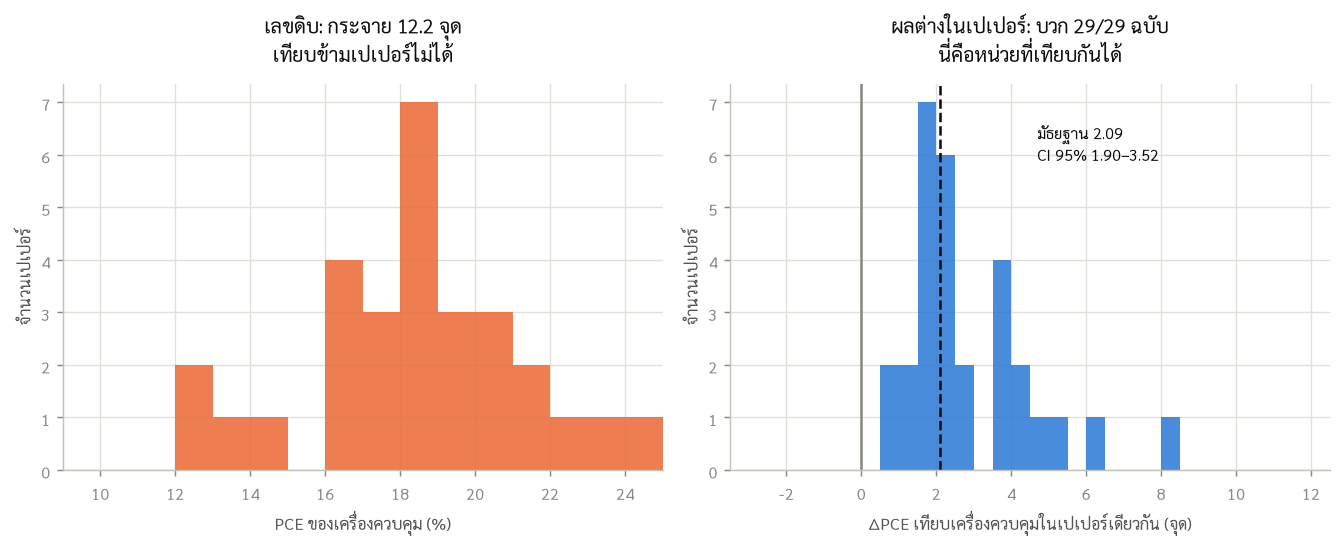

เปเปอร์ที่จับคู่ควบคุม/ดัดแปลงได้ 29 ฉบับ · ดีขึ้น 29 ฉบับ
มัธยฐาน ΔPCE = +2.09 จุด · CI 95% (bootstrap ระดับเปเปอร์) 1.90 ถึง 3.52
sign test p = 3.7e-09

เทียบกัน: sd ของเลขดิบข้ามเปเปอร์ = 2.93 จุด
          sd ของผลต่างในเปเปอร์   = 1.73 จุด


In [9]:
d = T["delta"].to_numpy()
n_p, k_pos = len(d), int((d > 0).sum())
p_sign = min(1.0, 2 * sum(comb(n_p, i) for i in range(k_pos, n_p + 1)) / 2 ** n_p)
rng = np.random.default_rng(0)
boot = np.median(rng.choice(d, size=(20000, n_p), replace=True), axis=1)
ci = np.percentile(boot, [2.5, 97.5])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 4.3))
SPAN = 16.0          # แกน x ของสองแผงกว้างเท่ากัน จะได้เทียบ "ความกระจาย" ด้วยตาได้ตรง ๆ

ax1.hist(T["ctrl"], bins=np.arange(9, 28, 1), color=CROSS, alpha=0.85)
ax1.set_xlim(9, 9 + SPAN)
ax1.set_xlabel("PCE ของเครื่องควบคุม (%)")
ax1.set_ylabel("จำนวนเปเปอร์")
ax1.set_title(f"เลขดิบ: กระจาย {T['ctrl'].max() - T['ctrl'].min():.1f} จุด\nเทียบข้ามเปเปอร์ไม่ได้", pad=12)

ax2.hist(d, bins=np.arange(0, 9.5, 0.5), color=IN_PAPER, alpha=0.85)
ax2.set_xlim(-3.5, -3.5 + SPAN)
ax2.axvline(0, color=MUTED, lw=1.4)
ax2.axvline(np.median(d), color=INK, lw=1.4, ls="--")
ax2.annotate(f"มัธยฐาน {np.median(d):.2f}\nCI 95% {ci[0]:.2f}–{ci[1]:.2f}",
             (np.median(d) + 2.6, ax2.get_ylim()[1] * 0.80), fontsize=8.6, color=INK)
ax2.set_xlabel("ΔPCE เทียบเครื่องควบคุมในเปเปอร์เดียวกัน (จุด)")
ax2.set_ylabel("จำนวนเปเปอร์")
ax2.set_title(f"ผลต่างในเปเปอร์: บวก {k_pos}/{n_p} ฉบับ\nนี่คือหน่วยที่เทียบกันได้", pad=12)
plt.tight_layout(); plt.show()

print(f"เปเปอร์ที่จับคู่ควบคุม/ดัดแปลงได้ {n_p} ฉบับ · ดีขึ้น {k_pos} ฉบับ")
print(f"มัธยฐาน ΔPCE = {np.median(d):+.2f} จุด · CI 95% (bootstrap ระดับเปเปอร์) {ci[0]:.2f} ถึง {ci[1]:.2f}")
print(f"sign test p = {p_sign:.2g}")
print(f"\nเทียบกัน: sd ของเลขดิบข้ามเปเปอร์ = {T['ctrl'].std():.2f} จุด")
print(f"          sd ของผลต่างในเปเปอร์   = {T['delta'].std():.2f} จุด")

### ข้อสรุปที่เอาไปใช้ได้

| ทำไม่ได้ | ทำได้แทน |
|---|---|
| เรียงลำดับ PCE ดิบข้ามเปเปอร์ | เรียงลำดับ **ΔPCE เทียบเครื่องควบคุมของเปเปอร์ตัวเอง** |
| หาค่าสหสัมพันธ์จากข้อมูลรวมทุกเปเปอร์ | คำนวณ**ภายในเปเปอร์**แล้วค่อยรวมผล (ดูหลักฐาน 5) |
| ฝึกแบบจำลองทำนาย PCE สัมบูรณ์ | ประมาณ**ขนาดของผล**พร้อมช่วงความเชื่อมั่น ด้วยสถิติแบบจับคู่ |
| สรุปว่า "สาร X ดีที่สุด" | สรุปได้แค่ว่า "**กลุ่ม**ของการดัดแปลงแบบนี้ให้ผลบวกอย่างสม่ำเสมอ" |
| นับอุปกรณ์เป็นขนาดตัวอย่าง | นับ**เปเปอร์**เป็นขนาดตัวอย่าง และใช้ bootstrap ระดับเปเปอร์ |

**ข้อจำกัดของบทพิสูจน์นี้เอง** ทุกตัวเลขข้างบนคำนวณจากสิ่งที่เปเปอร์รายงานไว้
เปเปอร์ไม่ได้รายงานทุกอย่าง (ความชื้นตอนเคลือบ อายุสารตั้งต้น ฝีมือคนทำ)
ซึ่งเป็นเหตุผลเพิ่มเติมว่าทำไมเส้นฐานถึงต่างกัน — ไม่ใช่ข้อโต้แย้งที่ทำให้เทียบข้ามเปเปอร์ได้